# ViDDAR — Entrega 2 (Fases 1-6)

```
ViDDAR — Entrega 2, versão SELF-CONTAINED (Fases 1-6)
========================================================

Arquivo independente: não depende de nenhuma célula rodada antes. Pode ser
colado do zero numa sessão nova do Colab, sem reinício de runtime no meio.

CACHE: a Seção [0] baixa o dataset e o checkpoint do SAM e SALVA NO DRIVE
(não em /content, que é apagado a cada reconexão). Da 2a vez em diante, ela
detecta que já existe e PULA o download — só a 1a execução é lenta (~3-5 min).

Seções:
  [0] Setup completo (GPU, Drive, repos, dataset com cache, Grounding DINO, funções)
  [1] Fix de determinismo + reexecução de v2/v3 com estatística (3x cada)
  [2] Inspeção qualitativa do caso fire-extinguisher_006
  [4] Opção B: adaptador condicionado por caixa (fine-tuning do mask decoder, estilo MedSAM)
  [5] Avaliação final no split de teste (62 imagens) — roda UMA VEZ só
  [6] Integração com decisão de obstrução + métricas completas (precision/recall/F1/FNR)

NOTA DE TEMPO: Seção [0] ~3-5 min na 1a vez (ou ~30s nas seguintes, graças ao cache).
Seção [1] ~70-75 min (treina 6 modelos). Seção [4] depende de N_EPOCHS_B, estimar
~15-30 min pra 40 épocas (mask decoder é leve). Seção [5]/[6] rápidas.
```

**Antes de rodar:** Ambiente de execução → Alterar tipo de execução → GPU (T4).

## [0] Setup completo, com cache no Drive

In [7]:
import os
import sys
import json
import random
import logging
import argparse
import zipfile
import subprocess
import shutil

import torch
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print("CUDA disponível:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA — ative em Ambiente de execução > Alterar tipo de execução")

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/viddar_samed'  # AJUSTAR se quiser outro caminho
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/data', exist_ok=True)

# cache do Hugging Face no disco local do Colab, NÃO no Drive: o safetensors lê
# os pesos via mmap e, no Drive, um arquivo parcialmente sincronizado quebra com
# "SafetensorError: header too large". Re-baixar ~700MB localmente leva <1 min.
shutil.rmtree(f'{PROJECT_DIR}/hf_cache', ignore_errors=True)
os.environ['HF_HOME'] = '/content/hf_cache'
os.makedirs(os.environ['HF_HOME'], exist_ok=True)

# --- 0a. Repositórios + checkpoint do SAM (clone é rápido, mas o checkpoint é
#     grande — esse sim fica cacheado no Drive) ---
if not os.path.exists('/content/segment-anything'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/segment-anything.git'], cwd='/content')
if not os.path.exists('/content/SAMed'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/hitachinsk/SAMed.git'], cwd='/content')
    subprocess.run(['pip', 'install', '-q', 'icecream', 'SimpleITK', 'medpy', 'tensorboardX', 'ml-collections'])

SAM_CKPT_DRIVE = f'{PROJECT_DIR}/checkpoints/sam_vit_b_01ec64.pth'
if not os.path.exists(SAM_CKPT_DRIVE):
    print("Baixando checkpoint do SAM (1a vez, ~375MB)...")
    subprocess.run(['wget', '-q', 'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth',
                     '-O', SAM_CKPT_DRIVE])
else:
    print("Checkpoint do SAM já em cache no Drive, pulando download.")

os.makedirs('/content/SAMed/checkpoints', exist_ok=True)
shutil.copy(SAM_CKPT_DRIVE, '/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')

# o SAMed tem sua própria cópia modificada de segment_anything; o repo original
# precisa ficar NA FRENTE no sys.path até a seção 0i, que troca a ordem.
sys.path.insert(0, '/content/SAMed')
sys.path.insert(0, '/content/segment-anything')


# --- 0b. Dataset ViDDAR, extraído DIRETO NO DRIVE (sobrevive a reconexões) ---
EXTRACT_DIR = f'{PROJECT_DIR}/data/extracted'
RAW_DIR = f'{EXTRACT_DIR}/raw_img/obstruction_raw_img'
AR_DIR = f'{EXTRACT_DIR}/ar_img/obstruction_ar_img'
KEY_MASK_DIR = f'{EXTRACT_DIR}/key_object_mask/obstruction_key_object_mask'

if not os.path.exists(RAW_DIR):
    print("Dataset ainda não extraído no Drive — baixando e extraindo (1a vez, alguns minutos)...")
    subprocess.run(['pip', 'install', '-q', 'gdown'])
    FOLDER_ID = '1aZ-2n-_DjUDqTJuQUbqMWiohOCxcp2UO'
    subprocess.run(['gdown', '--folder', f'https://drive.google.com/drive/folders/{FOLDER_ID}',
                     '-O', '/content/viddar_raw_tmp', '--remaining-ok'])

    os.makedirs(EXTRACT_DIR, exist_ok=True)
    for name, subdir in [
        ('obstruction_raw_img.zip', 'raw_img'),
        ('obstruction_ar_img.zip', 'ar_img'),
        ('obstruction_key_object_mask.zip', 'key_object_mask'),
        ('obstruction_ar_content_mask.zip', 'ar_content_mask'),
    ]:
        zpath = f'/content/viddar_raw_tmp/{name}'
        out = f'{EXTRACT_DIR}/{subdir}'
        os.makedirs(out, exist_ok=True)
        with zipfile.ZipFile(zpath) as z:
            z.extractall(out)
        print(f'{subdir}: {len(os.listdir(out))} itens extraídos')
    shutil.rmtree('/content/viddar_raw_tmp', ignore_errors=True)
else:
    print("Dataset já extraído no Drive, pulando download. "
          f"(raw: {len(os.listdir(RAW_DIR))}, ar: {len(os.listdir(AR_DIR))}, masks: {len(os.listdir(KEY_MASK_DIR))})")

if not os.path.exists('/content/ViDDAR-Dataset'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/YM-Xiu/ViDDAR-Dataset.git'], cwd='/content')

labels = pd.read_csv('/content/ViDDAR-Dataset/obstruction_labels.csv')
print(f'labels: {labels.shape}')

# --- 0c. Split treino/val/teste (gerado 1x, cacheado no Drive — NUNCA regenerar
#     depois disso, senão os números deixam de ser comparáveis entre sessões) ---
splits_path = f'{PROJECT_DIR}/splits.json'
if os.path.exists(splits_path):
    with open(splits_path) as f:
        splits = json.load(f)
    print(f"Splits carregados do cache: train={len(splits['train'])} val={len(splits['val'])} test={len(splits['test'])}")
else:
    from collections import defaultdict
    random.seed(42)
    by_class = defaultdict(list)
    for _, row in labels.iterrows():
        by_class[row['Object Name']].append(row['File Name'])
    train, val, test = [], [], []
    for cls, files in by_class.items():
        random.shuffle(files)
        n = len(files)
        n_train = max(1, int(0.70 * n))
        n_val = max(1, int(0.15 * n))
        train += files[:n_train]
        val += files[n_train:n_train + n_val]
        test += files[n_train + n_val:]
    splits = {'train': train, 'val': val, 'test': test}
    with open(splits_path, 'w') as f:
        json.dump(splits, f, indent=2)
    print(f"Splits gerados e salvos: train={len(train)} val={len(val)} test={len(test)}")

# --- 0d. Conversão .npz (224x224) pro treino do SAMed, cacheada ---
OUT_DIR = f'{PROJECT_DIR}/data/npz'
if not os.path.exists(f'{OUT_DIR}/train') or len(os.listdir(f'{OUT_DIR}/train')) == 0:
    print("Convertendo pares para .npz (1a vez)...")
    os.makedirs(OUT_DIR, exist_ok=True)

    def convert_pair(fname, img_size=224):
        raw_path = os.path.join(RAW_DIR, fname)
        mask_path = os.path.join(KEY_MASK_DIR, f'mask_{fname}')
        img = cv2.imread(raw_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            return None, None
        mask = cv2.resize(mask, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
        return img, mask

    for split_name, files in splits.items():
        split_dir = os.path.join(OUT_DIR, split_name)
        os.makedirs(split_dir, exist_ok=True)
        saved = 0
        for fname in files:
            img, mask = convert_pair(fname)
            if img is None:
                continue
            out_name = os.path.splitext(fname)[0] + '.npz'
            np.savez(os.path.join(split_dir, out_name), image=img, label=mask)
            saved += 1
        print(f'{split_name}: {saved}/{len(files)} salvos')
else:
    print("Conversão .npz já em cache no Drive, pulando.")

# --- 0e. dataset_viddar.py (precisa ser reescrito a cada runtime novo, é rápido) ---
dataset_viddar_code = '''
import os
import glob
import random
import numpy as np
import torch
import cv2
from torch.utils.data import Dataset


class RandomGenerator(object):
    def __init__(self, output_size, low_res):
        self.output_size = output_size
        self.low_res = low_res

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        if sample.get('augment', False) and random.random() > 0.5:
            image = np.ascontiguousarray(image[:, ::-1, :])
            label = np.ascontiguousarray(label[:, ::-1])
        h, w = label.shape
        if (h, w) != tuple(self.output_size):
            image = cv2.resize(image, (self.output_size[1], self.output_size[0]), interpolation=cv2.INTER_LINEAR)
            label = cv2.resize(label, (self.output_size[1], self.output_size[0]), interpolation=cv2.INTER_NEAREST)
        low_res_label = cv2.resize(label, (self.low_res[1], self.low_res[0]), interpolation=cv2.INTER_NEAREST)
        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)
        label = torch.from_numpy(label.astype(np.float32)).long()
        low_res_label = torch.from_numpy(low_res_label.astype(np.float32)).long()
        return {'image': image, 'label': label, 'low_res_label': low_res_label, 'case_name': sample['case_name']}


class Synapse_dataset(Dataset):
    def __init__(self, base_dir, list_dir=None, split='train', transform=None):
        self.split = split
        self.transform = transform
        self.data_dir = base_dir
        self.sample_list = sorted(glob.glob(os.path.join(base_dir, '*.npz')))

    def __len__(self):
        return len(self.sample_list)

    def __getitem__(self, idx):
        path = self.sample_list[idx]
        data = np.load(path)
        image, label = data['image'], data['label']
        case_name = os.path.splitext(os.path.basename(path))[0]
        sample = {'image': image, 'label': label, 'case_name': case_name, 'augment': (self.split == 'train')}
        if self.transform:
            sample = self.transform(sample)
        else:
            sample['image'] = torch.from_numpy(image.astype(np.float32) / 255.0).permute(2, 0, 1)
            sample['label'] = torch.from_numpy(label.astype(np.float32)).long()
        return sample
'''
with open('/content/SAMed/datasets/dataset_viddar.py', 'w') as f:
    f.write(dataset_viddar_code)

import importlib.util
spec = importlib.util.spec_from_file_location("datasets.dataset_synapse", "/content/SAMed/datasets/dataset_viddar.py")
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
sys.modules['datasets.dataset_synapse'] = mod

# --- 0f. Grounding DINO (nativo via transformers — sem clone, sem restart) ---
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

dino_model_id = "IDEA-Research/grounding-dino-tiny"
dino_processor = AutoProcessor.from_pretrained(dino_model_id)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(dino_model_id).to("cuda").eval()
print("Grounding DINO carregado.")

# --- 0g. SAM original + predictor ---
for mod_name in list(sys.modules.keys()):
    if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
        del sys.modules[mod_name]
sys.path.insert(0, '/content/segment-anything')

from segment_anything import sam_model_registry as sam_model_registry_orig, SamPredictor, SamAutomaticMaskGenerator

sam_baseline = sam_model_registry_orig['vit_b'](checkpoint='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')
sam_baseline.cuda()
predictor = SamPredictor(sam_baseline)
print("SAM original carregado.")


def reload_original_sam():
    """Recria uma instância limpa do SAM original — útil quando for alternar
    com o SAMed na mesma sessão (evita colisão de módulos em sys.modules)."""
    for mod_name in list(sys.modules.keys()):
        if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
            del sys.modules[mod_name]
    sys.path.insert(0, '/content/segment-anything')
    from segment_anything import sam_model_registry as _registry, SamPredictor as _Predictor
    sam = _registry['vit_b'](checkpoint='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')
    sam.cuda()
    return sam, _Predictor(sam)


# --- 0h. Funções auxiliares compartilhadas ---
def compute_iou_dice(pred, target, eps=1e-6):
    pred = pred.astype(bool)
    target = target.astype(bool)
    intersection = (pred & target).sum()
    union = (pred | target).sum()
    iou = (intersection + eps) / (union + eps)
    dice = (2 * intersection + eps) / (pred.sum() + target.sum() + eps)
    return iou, dice


def get_best_dino_box(image_pil, class_name, box_threshold=0.35, text_threshold=0.25):
    text_labels = [[class_name.lower()]]
    inputs = dino_processor(images=image_pil, text=text_labels, return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = dino_model(**inputs)
    results = dino_processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids, threshold=box_threshold, text_threshold=text_threshold,
        target_sizes=[image_pil.size[::-1]]
    )[0]
    if len(results['boxes']) == 0:
        return None
    best_idx = results['scores'].argmax().item()
    return results['boxes'][best_idx].cpu().numpy()


def get_virtual_content_mask(raw_path, ar_path, diff_threshold=30):
    raw = cv2.imread(raw_path)
    ar = cv2.imread(ar_path)
    if raw.shape != ar.shape:
        ar = cv2.resize(ar, (raw.shape[1], raw.shape[0]))
    diff = cv2.absdiff(raw, ar)
    diff_gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
    return (diff_gray > diff_threshold).astype(np.uint8)


# --- 0i. Funções do SAMed (precisam do import feito DEPOIS do reload_original_sam
#     acima, pra pegar a versão vendorizada correta) ---
for mod_name in list(sys.modules.keys()):
    if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
        del sys.modules[mod_name]
sys.path.insert(0, '/content/SAMed')
from sam_lora_image_encoder import LoRA_Sam
from segment_anything import sam_model_registry
from trainer import trainer_synapse
import trainer as trainer_mod
import torch.nn.functional as F
import re


def build_samed_model(args):
    sam, img_embedding_size = sam_model_registry[args.vit_name](
        image_size=args.img_size, num_classes=args.num_classes, checkpoint=args.ckpt,
        pixel_mean=[0, 0, 0], pixel_std=[1, 1, 1],
    )
    net = LoRA_Sam(sam, args.rank).cuda()
    return net, img_embedding_size


def plot_loss_curve(snapshot_path, title):
    log_path = f'{snapshot_path}/log.txt'
    iters, losses = [], []
    with open(log_path) as f:
        for line in f:
            m = re.search(r'iteration (\d+) : loss : ([\d.]+)', line)
            if m:
                iters.append(int(m.group(1)))
                losses.append(float(m.group(2)))
    plt.figure(figsize=(10, 4))
    plt.plot(iters, losses, linewidth=0.8)
    plt.xlabel('Iteração'); plt.ylabel('Loss total'); plt.title(title)
    plt.show()
    print(f'Loss mínima: {min(losses):.4f} na iteração {iters[losses.index(min(losses))]}')
    print(f'Últimas 10: {losses[-10:]}')


def evaluate_samed(net, args, multimask_output, low_res, val_dir):
    val_ds = mod.Synapse_dataset(
        base_dir=val_dir, split='val',
        transform=mod.RandomGenerator(output_size=[args.img_size, args.img_size], low_res=[low_res, low_res])
    )
    ious, dices = [], []
    with torch.no_grad():
        for i in range(len(val_ds)):
            sample = val_ds[i]
            image = sample['image'].unsqueeze(0).cuda()
            label = sample['label'].numpy()
            outputs = net(image, multimask_output, args.img_size)
            logits_full = F.interpolate(outputs['low_res_logits'], size=(args.img_size, args.img_size),
                                         mode='bilinear', align_corners=False)
            pred = torch.argmax(logits_full, dim=1).squeeze(0).cpu().numpy()
            iou, dice = compute_iou_dice(pred, label)
            ious.append(iou); dices.append(dice)
    print(f'Validação ({len(val_ds)}): IoU {np.mean(ious):.4f} | Dice {np.mean(dices):.4f} '
          f'| IoU min {np.min(ious):.4f} / max {np.max(ious):.4f}')
    return val_ds, ious, dices


print("\n=== Setup completo. Variáveis disponíveis: labels, splits, RAW_DIR, AR_DIR, KEY_MASK_DIR, ")
print("OUT_DIR, PROJECT_DIR, dino_processor, dino_model, sam_baseline, predictor, mod, trainer_synapse,")
print("build_samed_model, evaluate_samed, plot_loss_curve, compute_iou_dice, get_best_dino_box,")
print("get_virtual_content_mask, reload_original_sam ===\n")

CUDA disponível: True
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint do SAM já em cache no Drive, pulando download.
Dataset já extraído no Drive, pulando download. (raw: 306, ar: 306, masks: 322)
labels: (306, 3)
Splits carregados do cache: train=207 val=37 test=62
Conversão .npz já em cache no Drive, pulando.


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO carregado.
SAM original carregado.

=== Setup completo. Variáveis disponíveis: labels, splits, RAW_DIR, AR_DIR, KEY_MASK_DIR, 
OUT_DIR, PROJECT_DIR, dino_processor, dino_model, sam_baseline, predictor, mod, trainer_synapse,
build_samed_model, evaluate_samed, plot_loss_curve, compute_iou_dice, get_best_dino_box,
get_virtual_content_mask, reload_original_sam ===



## [1] Fix de determinismo + estatística v2 vs v3 (3 rodadas cada)

In [8]:
_OrigDataLoader = trainer_mod.DataLoader


def _deterministic_dataloader(*a, **kw):
    kw['num_workers'] = 0
    return _OrigDataLoader(*a, **kw)


trainer_mod.DataLoader = _deterministic_dataloader
print("DataLoader do trainer.py monkeypatchado pra num_workers=0 (determinismo).")


def run_samed_training(dice_param, run_name, n_runs=3, base_lr=0.001, warmup_period=400, max_epochs=80):
    results = []
    for rep in range(1, n_runs + 1):
        args = argparse.Namespace(
            root_path=f'{OUT_DIR}/train', list_dir=None, dataset='Synapse', num_classes=2,
            batch_size=4, base_lr=base_lr, img_size=224, vit_name='vit_b',
            ckpt='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth', rank=4,
            warmup=True, warmup_period=warmup_period, AdamW=True, max_epochs=max_epochs, stop_epoch=max_epochs,
            deterministic=1, seed=1234, n_gpu=1, module='sam_lora_image_encoder', dice_param=dice_param,
        )
        net, img_embedding_size = build_samed_model(args)
        multimask_output = args.num_classes > 1
        low_res = img_embedding_size * 4

        snapshot_path = f'{PROJECT_DIR}/checkpoints/{run_name}_rep{rep}'
        os.makedirs(snapshot_path, exist_ok=True)
        logging.root.handlers = []
        trainer_synapse(args, net, snapshot_path, multimask_output, low_res)

        net.load_lora_parameters(f'{snapshot_path}/epoch_{max_epochs - 1}.pth')
        net.eval()
        _, ious, dices = evaluate_samed(net, args, multimask_output, low_res, f'{OUT_DIR}/val')
        results.append((np.mean(ious), np.mean(dices)))
        print(f'[{run_name} rep{rep}] IoU={np.mean(ious):.4f} | Dice={np.mean(dices):.4f}\n')

    return results


results_v2 = run_samed_training(dice_param=0.8, run_name='stat_v2')
results_v3 = run_samed_training(dice_param=0.9, run_name='stat_v3')

ious_v2 = [r[0] for r in results_v2]
ious_v3 = [r[0] for r in results_v3]

print('=' * 60)
print(f'v2 (dice_param=0.8): IoU = {np.mean(ious_v2):.4f} ± {np.std(ious_v2):.4f}  (rodadas: {[f"{x:.4f}" for x in ious_v2]})')
print(f'v3 (dice_param=0.9): IoU = {np.mean(ious_v3):.4f} ± {np.std(ious_v3):.4f}  (rodadas: {[f"{x:.4f}" for x in ious_v3]})')
diff = np.mean(ious_v3) - np.mean(ious_v2)
pooled_std = np.sqrt((np.std(ious_v2)**2 + np.std(ious_v3)**2) / 2)
print(f'Diferença das médias: {diff:+.4f} | desvio-padrão combinado (ref.): {pooled_std:.4f}')
print('=> Se |diferença| for menor que ~1-2x o desvio combinado, trate como "sem diferença distinguível do ruído".')
print('=' * 60)

DataLoader do trainer.py monkeypatchado pra num_workers=0 (determinismo).
Namespace(root_path='/content/drive/MyDrive/viddar_samed/data/npz/train', list_dir=None, dataset='Synapse', num_classes=2, batch_size=4, base_lr=0.001, img_size=224, vit_name='vit_b', ckpt='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth', rank=4, warmup=True, warmup_period=400, AdamW=True, max_epochs=80, stop_epoch=80, deterministic=1, seed=1234, n_gpu=1, module='sam_lora_image_encoder', dice_param=0.8)
The length of train set is: 207
52 iterations per epoch. 4160 max iterations 


  0%|                                          | 0/80 [00:00<?, ?it/s]

iteration 1 : loss : 1.498643, loss_ce: 4.073116, loss_dice: 0.855025
iteration 2 : loss : 1.652040, loss_ce: 4.897943, loss_dice: 0.840565
iteration 3 : loss : 1.446185, loss_ce: 3.754272, loss_dice: 0.869163
iteration 4 : loss : 1.427255, loss_ce: 3.632167, loss_dice: 0.876027
iteration 5 : loss : 1.032704, loss_ce: 1.958845, loss_dice: 0.801169
iteration 6 : loss : 1.053952, loss_ce: 2.056504, loss_dice: 0.803314
iteration 7 : loss : 1.120177, loss_ce: 2.261231, loss_dice: 0.834913
iteration 8 : loss : 1.085494, loss_ce: 2.131207, loss_dice: 0.824065
iteration 9 : loss : 0.925225, loss_ce: 1.572771, loss_dice: 0.763338
iteration 10 : loss : 1.064027, loss_ce: 1.979451, loss_dice: 0.835171
iteration 11 : loss : 0.970893, loss_ce: 1.642940, loss_dice: 0.802881
iteration 12 : loss : 1.028632, loss_ce: 1.859514, loss_dice: 0.820911
iteration 13 : loss : 0.821259, loss_ce: 1.113797, loss_dice: 0.748125
iteration 14 : loss : 0.787837, loss_ce: 0.978197, loss_dice: 0.740247
iteration 15 : 

  1%|▍                                 | 1/80 [00:13<18:14, 13.86s/it]

iteration 53 : loss : 0.511527, loss_ce: 0.197641, loss_dice: 0.589998
iteration 54 : loss : 0.486769, loss_ce: 0.148517, loss_dice: 0.571332
iteration 55 : loss : 0.439217, loss_ce: 0.107418, loss_dice: 0.522167
iteration 56 : loss : 0.375284, loss_ce: 0.141028, loss_dice: 0.433848
iteration 57 : loss : 0.394770, loss_ce: 0.113814, loss_dice: 0.465009
iteration 58 : loss : 0.428857, loss_ce: 0.132299, loss_dice: 0.502997
iteration 59 : loss : 0.323799, loss_ce: 0.040068, loss_dice: 0.394732
iteration 60 : loss : 0.525905, loss_ce: 0.159037, loss_dice: 0.617622
iteration 61 : loss : 0.419995, loss_ce: 0.133113, loss_dice: 0.491715
iteration 62 : loss : 0.450378, loss_ce: 0.076516, loss_dice: 0.543844
iteration 63 : loss : 0.485569, loss_ce: 0.075862, loss_dice: 0.587995
iteration 64 : loss : 0.396968, loss_ce: 0.058826, loss_dice: 0.481503
iteration 65 : loss : 0.436976, loss_ce: 0.047637, loss_dice: 0.534310
iteration 66 : loss : 0.407436, loss_ce: 0.102660, loss_dice: 0.483631
iterat

  2%|▊                                 | 2/80 [00:22<13:40, 10.52s/it]

... (963 outputs left out)

 99%|████████████████████████████████▌| 79/80 [11:47<00:08,  8.99s/it]

iteration 4109 : loss : 0.006647, loss_ce: 0.001831, loss_dice: 0.007182
iteration 4110 : loss : 0.005737, loss_ce: 0.004360, loss_dice: 0.005890
iteration 4111 : loss : 0.013591, loss_ce: 0.009746, loss_dice: 0.014018
iteration 4112 : loss : 0.011923, loss_ce: 0.006791, loss_dice: 0.012493
iteration 4113 : loss : 0.011584, loss_ce: 0.008908, loss_dice: 0.011882
iteration 4114 : loss : 0.016326, loss_ce: 0.014658, loss_dice: 0.016512
iteration 4115 : loss : 0.007350, loss_ce: 0.008884, loss_dice: 0.007180
iteration 4116 : loss : 0.008489, loss_ce: 0.010728, loss_dice: 0.008240
iteration 4117 : loss : 0.024127, loss_ce: 0.018975, loss_dice: 0.024699
iteration 4118 : loss : 0.007065, loss_ce: 0.005810, loss_dice: 0.007205
iteration 4119 : loss : 0.009687, loss_ce: 0.006593, loss_dice: 0.010031
iteration 4120 : loss : 0.009333, loss_ce: 0.006547, loss_dice: 0.009643
iteration 4121 : loss : 0.008505, loss_ce: 0.006070, loss_dice: 0.008776
iteration 4122 : loss : 0.010677, loss_ce: 0.009345

 99%|████████████████████████████████▌| 79/80 [11:56<00:09,  9.07s/it]


Validação (37): IoU 0.6284 | Dice 0.7213 | IoU min 0.0000 / max 0.9339
[stat_v3 rep3] IoU=0.6284 | Dice=0.7213

v2 (dice_param=0.8): IoU = 0.6487 ± 0.0172  (rodadas: ['0.6609', '0.6609', '0.6244'])
v3 (dice_param=0.9): IoU = 0.6296 ± 0.0131  (rodadas: ['0.6141', '0.6463', '0.6284'])
Diferença das médias: -0.0191 | desvio-padrão combinado (ref.): 0.0153
=> Se |diferença| for menor que ~1-2x o desvio combinado, trate como "sem diferença distinguível do ruído".


### Escolha do modelo
Ajuste os valores abaixo com base nos resultados de v2/v3 impressos acima e rode esta célula antes da Seção [2].

In [9]:
# AJUSTAR MANUALMENTE depois de ver os números acima:
CHOSEN_DICE_PARAM = 0.8
CHOSEN_RUN_NAME = 'stat_v2'
CHOSEN_REP = 1

## [2] Inspeção qualitativa — fire-extinguisher_006

fire-extinguisher_006: IoU = 0.0000 | Dice = 0.0000 | pixels GT = 15388 | pixels preditos = 67949


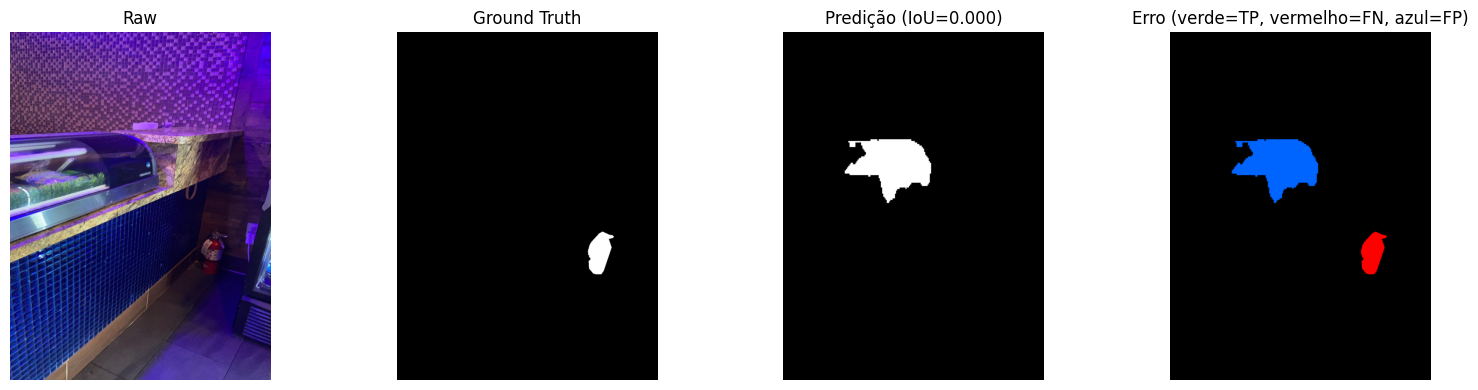

In [10]:
args_final = argparse.Namespace(
    root_path=f'{OUT_DIR}/train', list_dir=None, dataset='Synapse', num_classes=2,
    batch_size=4, base_lr=0.001, img_size=224, vit_name='vit_b',
    ckpt='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth', rank=4,
    warmup=True, warmup_period=400, AdamW=True, max_epochs=80, stop_epoch=80,
    deterministic=1, seed=1234, n_gpu=1, module='sam_lora_image_encoder', dice_param=CHOSEN_DICE_PARAM,
)
net_final, img_embedding_size_final = build_samed_model(args_final)
multimask_output_final = args_final.num_classes > 1
low_res_final = img_embedding_size_final * 4
net_final.load_lora_parameters(f'{PROJECT_DIR}/checkpoints/{CHOSEN_RUN_NAME}_rep{CHOSEN_REP}/epoch_79.pth')
net_final.eval()

case_name = 'fire-extinguisher_006'
fname = f'{case_name}.png'

raw_path = os.path.join(RAW_DIR, fname)
mask_path = os.path.join(KEY_MASK_DIR, f'mask_{fname}')
raw_img = Image.open(raw_path).convert("RGB")
gt_mask = (cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)

img_224 = cv2.resize(np.array(raw_img), (224, 224)) / 255.0
img_tensor = torch.from_numpy(img_224).permute(2, 0, 1).unsqueeze(0).float().cuda()
with torch.no_grad():
    outputs = net_final(img_tensor, multimask_output_final, args_final.img_size)
    logits_full = F.interpolate(outputs['low_res_logits'], size=(224, 224), mode='bilinear', align_corners=False)
    pred_224 = torch.argmax(logits_full, dim=1).squeeze(0).cpu().numpy()
pred_mask = cv2.resize(pred_224.astype(np.uint8), (gt_mask.shape[1], gt_mask.shape[0]), interpolation=cv2.INTER_NEAREST)

iou, dice = compute_iou_dice(pred_mask, gt_mask)
print(f'{case_name}: IoU = {iou:.4f} | Dice = {dice:.4f} | pixels GT = {gt_mask.sum()} | pixels preditos = {pred_mask.sum()}')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(raw_img); axes[0].set_title('Raw')
axes[1].imshow(gt_mask, cmap='gray'); axes[1].set_title('Ground Truth')
axes[2].imshow(pred_mask, cmap='gray'); axes[2].set_title(f'Predição (IoU={iou:.3f})')

error_map = np.zeros((*gt_mask.shape, 3), dtype=np.uint8)
error_map[(gt_mask == 1) & (pred_mask == 1)] = [0, 200, 0]
error_map[(gt_mask == 1) & (pred_mask == 0)] = [255, 0, 0]
error_map[(gt_mask == 0) & (pred_mask == 1)] = [0, 100, 255]
axes[3].imshow(error_map); axes[3].set_title('Erro (verde=TP, vermelho=FN, azul=FP)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/fig_fire_extinguisher_case.png', dpi=200, bbox_inches='tight')
plt.show()

## [4] Opção B — adaptador condicionado por caixa (fine-tuning do mask decoder)

pré-computando caixas (train_boxes.json):   0%|          | 0/207 [00:00<?, ?it/s]

pré-computando caixas (val_boxes.json):   0%|          | 0/37 [00:00<?, ?it/s]

Opção B — treino: 202/207 | val: 37/37
Parâmetros treináveis (mask decoder): 4,058,340


Opção B — época 1/40:   0%|          | 0/202 [00:00<?, ?it/s]

Época 1/40 — loss média: 0.5842


Opção B — época 2/40:   0%|          | 0/202 [00:00<?, ?it/s]

... (73 outputs left out)

Opção B — época 39/40:   0%|          | 0/202 [00:00<?, ?it/s]

Época 39/40 — loss média: 0.1712


Opção B — época 40/40:   0%|          | 0/202 [00:00<?, ?it/s]

Época 40/40 — loss média: 0.1797


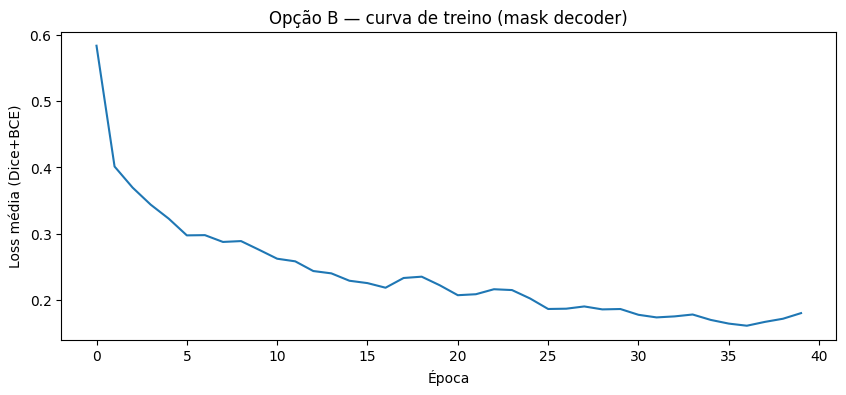

Avaliando Opção B:   0%|          | 0/37 [00:00<?, ?it/s]

Opção B — Val (37): IoU 0.0885 | Dice 0.1345

Comparação direta — mesma arquitetura SAM ViT-B, mesmo split de validação:
  Opção A (promptless, stat_v2): IoU 0.6487
  Opção B (caixa DINO + mask decoder fine-tuned): IoU 0.0885
  SAM + caixa oracular (referência, teto): IoU ~0.886 (valor de sessões anteriores)


In [11]:
import torch.nn as nn
from segment_anything.utils.transforms import ResizeLongestSide

resize_transform = ResizeLongestSide(sam_baseline.image_encoder.img_size)


def precompute_boxes(file_list, cache_path):
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            return json.load(f)
    boxes = {}
    for fname in tqdm(file_list, desc=f'pré-computando caixas ({os.path.basename(cache_path)})'):
        row = labels[labels['File Name'] == fname].iloc[0]
        image_pil = Image.open(os.path.join(RAW_DIR, fname)).convert("RGB")
        box = get_best_dino_box(image_pil, row['Object Name'])
        boxes[fname] = box.tolist() if box is not None else None
    with open(cache_path, 'w') as f:
        json.dump(boxes, f)
    return boxes


train_boxes = precompute_boxes(splits['train'], f'{PROJECT_DIR}/train_boxes.json')
val_boxes = precompute_boxes(splits['val'], f'{PROJECT_DIR}/val_boxes.json')

train_files_b = [f for f in splits['train'] if train_boxes[f] is not None]
val_files_b = [f for f in splits['val'] if val_boxes[f] is not None]
print(f'Opção B — treino: {len(train_files_b)}/{len(splits["train"])} | val: {len(val_files_b)}/{len(splits["val"])}')


def prepare_sample(fname, box_dict, sam):
    raw_path = os.path.join(RAW_DIR, fname)
    mask_path = os.path.join(KEY_MASK_DIR, f'mask_{fname}')
    image = cv2.cvtColor(cv2.imread(raw_path), cv2.COLOR_BGR2RGB)
    gt_mask = (cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    box = np.array(box_dict[fname])

    input_image = resize_transform.apply_image(image)
    input_image_torch = torch.as_tensor(input_image, device='cuda').permute(2, 0, 1).contiguous()[None, :, :, :]
    input_image_torch = sam.preprocess(input_image_torch)

    box_transformed = resize_transform.apply_boxes(box[None, :], image.shape[:2])
    box_torch = torch.as_tensor(box_transformed, dtype=torch.float, device='cuda')

    gt_mask_resized = cv2.resize(gt_mask, (256, 256), interpolation=cv2.INTER_NEAREST)
    gt_tensor = torch.as_tensor(gt_mask_resized, dtype=torch.float, device='cuda')[None, None, :, :]

    return input_image_torch, box_torch, gt_tensor, gt_mask, image.shape[:2]


def dice_bce_loss(pred_logits, target, eps=1e-6):
    pred_prob = torch.sigmoid(pred_logits)
    intersection = (pred_prob * target).sum()
    dice_loss = 1 - (2 * intersection + eps) / (pred_prob.sum() + target.sum() + eps)
    bce_loss = F.binary_cross_entropy_with_logits(pred_logits, target)
    return dice_loss + bce_loss


sam_b, _ = reload_original_sam()
for param in sam_b.image_encoder.parameters():
    param.requires_grad = False
for param in sam_b.prompt_encoder.parameters():
    param.requires_grad = False
for param in sam_b.mask_decoder.parameters():
    param.requires_grad = True

trainable_params = [p for p in sam_b.mask_decoder.parameters() if p.requires_grad]
print(f'Parâmetros treináveis (mask decoder): {sum(p.numel() for p in trainable_params):,}')

optimizer_b = torch.optim.AdamW(trainable_params, lr=1e-4)

N_EPOCHS_B = 40
snapshot_path_b = f'{PROJECT_DIR}/checkpoints/option_b_maskdecoder'
os.makedirs(snapshot_path_b, exist_ok=True)

loss_history_b = []
sam_b.train()

for epoch in range(N_EPOCHS_B):
    epoch_losses = []
    random.shuffle(train_files_b)
    for fname in tqdm(train_files_b, desc=f'Opção B — época {epoch+1}/{N_EPOCHS_B}', leave=False):
        input_image_torch, box_torch, gt_tensor, _, _ = prepare_sample(fname, train_boxes, sam_b)

        with torch.no_grad():
            image_embedding = sam_b.image_encoder(input_image_torch)
            sparse_emb, dense_emb = sam_b.prompt_encoder(points=None, boxes=box_torch, masks=None)

        low_res_masks, _ = sam_b.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=sam_b.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_emb,
            dense_prompt_embeddings=dense_emb,
            multimask_output=False,
        )

        loss = dice_bce_loss(low_res_masks, gt_tensor)
        optimizer_b.zero_grad()
        loss.backward()
        optimizer_b.step()
        epoch_losses.append(loss.item())

    mean_loss = np.mean(epoch_losses)
    loss_history_b.append(mean_loss)
    print(f'Época {epoch+1}/{N_EPOCHS_B} — loss média: {mean_loss:.4f}')

    if (epoch + 1) % 10 == 0 or epoch == N_EPOCHS_B - 1:
        torch.save(sam_b.mask_decoder.state_dict(), f'{snapshot_path_b}/mask_decoder_epoch{epoch+1}.pth')

plt.figure(figsize=(10, 4))
plt.plot(loss_history_b)
plt.xlabel('Época'); plt.ylabel('Loss média (Dice+BCE)'); plt.title('Opção B — curva de treino (mask decoder)')
plt.show()


def evaluate_option_b(sam, file_list, box_dict):
    sam.eval()
    ious, dices = [], []
    with torch.no_grad():
        for fname in tqdm(file_list, desc='Avaliando Opção B'):
            input_image_torch, box_torch, _, gt_mask, original_size = prepare_sample(fname, box_dict, sam)
            image_embedding = sam.image_encoder(input_image_torch)
            sparse_emb, dense_emb = sam.prompt_encoder(points=None, boxes=box_torch, masks=None)
            low_res_masks, _ = sam.mask_decoder(
                image_embeddings=image_embedding, image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb, multimask_output=False,
            )
            upscaled = sam.postprocess_masks(low_res_masks, input_size=tuple(resize_transform.apply_image(
                np.zeros((*original_size, 3), dtype=np.uint8)).shape[:2]), original_size=original_size)
            pred_mask = (upscaled.squeeze().cpu().numpy() > 0).astype(np.uint8)
            iou, dice = compute_iou_dice(pred_mask, gt_mask)
            ious.append(iou); dices.append(dice)
    print(f'Opção B — Val ({len(file_list)}): IoU {np.mean(ious):.4f} | Dice {np.mean(dices):.4f}')
    return ious, dices


ious_b, dices_b = evaluate_option_b(sam_b, val_files_b, val_boxes)
print(f'\nComparação direta — mesma arquitetura SAM ViT-B, mesmo split de validação:')
print(f'  Opção A (promptless, {CHOSEN_RUN_NAME}): IoU {np.mean(ious_v2 if CHOSEN_RUN_NAME=="stat_v2" else ious_v3):.4f}')
print(f'  Opção B (caixa DINO + mask decoder fine-tuned): IoU {np.mean(ious_b):.4f}')
print(f'  SAM + caixa oracular (referência, teto): IoU ~0.886 (valor de sessões anteriores)')

## [5] Avaliação final no split de TESTE (62 imagens) — rodar UMA VEZ só

In [12]:
test_files = splits['test']
test_boxes = precompute_boxes(test_files, f'{PROJECT_DIR}/test_boxes.json')
test_files_b = [f for f in test_files if test_boxes[f] is not None]

print('=== AVALIAÇÃO FINAL NO TESTE — não repetir, não ajustar hiperparâmetro depois disso ===\n')

_, ious_test_a, dices_test_a = evaluate_samed(net_final, args_final, multimask_output_final, low_res_final, f'{OUT_DIR}/test')
print(f'Opção A (promptless) — Teste ({len(test_files)}): IoU {np.mean(ious_test_a):.4f} | Dice {np.mean(dices_test_a):.4f}')

ious_test_b, dices_test_b = evaluate_option_b(sam_b, test_files_b, test_boxes)

pré-computando caixas (test_boxes.json):   0%|          | 0/62 [00:00<?, ?it/s]

=== AVALIAÇÃO FINAL NO TESTE — não repetir, não ajustar hiperparâmetro depois disso ===

Validação (62): IoU 0.7377 | Dice 0.8255 | IoU min 0.0000 / max 0.9495
Opção A (promptless) — Teste (62): IoU 0.7377 | Dice 0.8255


Avaliando Opção B:   0%|          | 0/61 [00:00<?, ?it/s]

Opção B — Val (61): IoU 0.0961 | Dice 0.1520


## [6] Integração com decisão de obstrução + métricas completas

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix


def predict_mask_option_a(fname):
    raw_img = Image.open(os.path.join(RAW_DIR, fname)).convert("RGB")
    img_224 = cv2.resize(np.array(raw_img), (224, 224)) / 255.0
    img_tensor = torch.from_numpy(img_224).permute(2, 0, 1).unsqueeze(0).float().cuda()
    with torch.no_grad():
        outputs = net_final(img_tensor, multimask_output_final, args_final.img_size)
        logits_full = F.interpolate(outputs['low_res_logits'], size=raw_img.size[::-1],
                                     mode='bilinear', align_corners=False)
        pred = torch.argmax(logits_full, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)
    return pred


def predict_mask_option_b(fname):
    input_image_torch, box_torch, _, gt_mask, original_size = prepare_sample(fname, test_boxes, sam_b)
    with torch.no_grad():
        image_embedding = sam_b.image_encoder(input_image_torch)
        sparse_emb, dense_emb = sam_b.prompt_encoder(points=None, boxes=box_torch, masks=None)
        low_res_masks, _ = sam_b.mask_decoder(
            image_embeddings=image_embedding, image_pe=sam_b.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb, multimask_output=False,
        )
        upscaled = sam_b.postprocess_masks(low_res_masks, input_size=tuple(resize_transform.apply_image(
            np.zeros((*original_size, 3), dtype=np.uint8)).shape[:2]), original_size=original_size)
    return (upscaled.squeeze().cpu().numpy() > 0).astype(np.uint8)


def evaluate_obstruction_full_metrics(predict_fn, file_list, label_name):
    preds, gts = [], []
    for fname in tqdm(file_list, desc=f'Obstrução — {label_name}'):
        pred_mask = predict_fn(fname)

        raw_path = os.path.join(RAW_DIR, fname)
        ar_path = os.path.join(AR_DIR, f'AR_{fname}')
        m_c = get_virtual_content_mask(raw_path, ar_path)
        if m_c.shape != pred_mask.shape:
            m_c = cv2.resize(m_c, (pred_mask.shape[1], pred_mask.shape[0]))

        overlap = (pred_mask & m_c).sum()
        ratio = overlap / (pred_mask.sum() + 1e-6)
        pred_obstructed = ratio >= 0.25

        gt_row = labels[labels['File Name'] == fname].iloc[0]
        gt_obstructed = gt_row['obstruction'] == 'yes'

        preds.append(pred_obstructed)
        gts.append(gt_obstructed)

    preds, gts = np.array(preds), np.array(gts)
    acc = (preds == gts).mean()
    prec = precision_score(gts, preds, zero_division=0)
    rec = recall_score(gts, preds, zero_division=0)
    f1 = f1_score(gts, preds, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(gts, preds).ravel()
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    print(f'\n--- {label_name} ---')
    print(f'Acurácia: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | FNR: {fnr:.4f}')
    print(f'Matriz de confusão — TN:{tn} FP:{fp} FN:{fn} TP:{tp}')
    return {'acc': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'fnr': fnr,
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}


results_obstruction_a = evaluate_obstruction_full_metrics(predict_mask_option_a, test_files, 'Opção A (promptless) — teste')
results_obstruction_b = evaluate_obstruction_full_metrics(predict_mask_option_b, test_files_b, 'Opção B (caixa DINO) — teste')

summary_df = pd.DataFrame([results_obstruction_a, results_obstruction_b], index=['Opção A', 'Opção B'])
summary_df.to_csv(f'{PROJECT_DIR}/obstruction_full_metrics.csv')
print('\nResumo salvo em obstruction_full_metrics.csv:')
print(summary_df)

Obstrução — Opção A (promptless) — teste:   0%|          | 0/62 [00:00<?, ?it/s]


--- Opção A (promptless) — teste ---
Acurácia: 0.9032 | Precision: 0.9583 | Recall: 0.8214 | F1: 0.8846 | FNR: 0.1786
Matriz de confusão — TN:33 FP:1 FN:5 TP:23


Obstrução — Opção B (caixa DINO) — teste:   0%|          | 0/61 [00:00<?, ?it/s]


--- Opção B (caixa DINO) — teste ---
Acurácia: 0.7541 | Precision: 0.7308 | Recall: 0.7037 | F1: 0.7170 | FNR: 0.2963
Matriz de confusão — TN:27 FP:7 FN:8 TP:19

Resumo salvo em obstruction_full_metrics.csv:
              acc  precision    recall        f1       fnr  tn  fp  fn  tp
Opção A  0.903226   0.958333  0.821429  0.884615  0.178571  33   1   5  23
Opção B  0.754098   0.730769  0.703704  0.716981  0.296296  27   7   8  19
